## Distribuição de probabilidade
## Livro de referência: Livro "Practical statistics for data scientists + 50+ essential concepts using R and Pyhton" - Bruce, Bruce & Gedeck

In [1]:
# erro estatístico - reflexo natural da variabilidade de uma determinada variável
# viés estatístico - é um erro sistemático, que empurra os dados em uma direção constantemente
    # viés de seleção - os dados que "sobreviveram"; a análise não considera dados amplos
    # seleção de autoviés - a análise é feita por extremos; ex: a análise de comentários de restaurantes onde só quem detestou a comida escreveu algo
    # data snooping - "tortura de dados", padrões e respostas que os analistas encontram após análise extensiva dos dados

In [2]:
# regressão à média
# fênomeno estatístico em que as amostras tendem a retornar ao resultado médio, porém este resultado costuma ser mascarado por intervenções externas
# ex: o chefe que interviu nos resultados de uma equipe que baixaram em um mês e no mês seguinte retornam à média histórica

In [3]:
# amostragem aleatória
# processo de seleção estruturado de forma a que nenhum subgrupo da população seja excluído durante as análises
# visa eliminar o erro de viés estatístico, mantendo somente erros aleatórios
# ex: em uma pesquisa eleitoral, é importante manter os diversos subgrupos que representam a sociedade, de forma a que não haja enviesamento em função de
# identificação com campo político

In [4]:
# amostragem estratificada
# seleção de amostra por subgrupo para entender o comportamento e representatividade de cada um
# ex: subgrupo por gênero, idade etc em uma pesquisa eleitoral

In [5]:
# distribuição de dados - como os valores individuais se distribuem
# distribuição amostral de uma estatística - distribuição obtida caso se calculasse uma estatística em amostras diferentes dentro da mesma população
    # ex: calcular a média salarial em grupos de 50 pessoas dentro de uma mesma população
# a distribuição amostral tende a ser mais estreita - é mais estável
# tende a ser mais normal (em formato de sino) do que os dados originais - Teora Central do Limite
# quanto maior a amostra, mais estreita e normal ela fica

In [6]:
# Erro padrão
# medida que captura a variabilidade da distribuição amostral
# tecnicamente, é o desvio padrão da distribuição amostral de uma estatística
# se eu repetir o cálculo da estatística em amostras diferentes do mesmo tamanho extraído da mesma população, a variabilidade gira em torno de um valor
# populacional, com desvio padrão; esse é o desvio padrão
# quando maior o tamanho da amostra, menor o erro padrão
# SE = desvio padrão / raiz da amostra

In [7]:
# importações
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt
import math

In [8]:
jobs = pd.read_csv("jobs_in_data_2024.csv",sep=",")

In [9]:
# Reconhecimento inicial
jobs.shape
jobs.info()
jobs.head()
jobs.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14199 entries, 0 to 14198
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           14199 non-null  int64 
 1   experience_level    14199 non-null  object
 2   employment_type     14199 non-null  object
 3   job_title           14199 non-null  object
 4   salary              14199 non-null  int64 
 5   salary_currency     14199 non-null  object
 6   salary_in_usd       14199 non-null  int64 
 7   employee_residence  14199 non-null  object
 8   work_setting        14199 non-null  object
 9   company_location    14199 non-null  object
 10  company_size        14199 non-null  object
 11  job_category        14199 non-null  object
dtypes: int64(3), object(9)
memory usage: 1.3+ MB


,work_year,salary,salary_in_usd
count,14199.000000,14199.000000,14199.00000
mean,2023.110501,149057.514262,149472.04944
std,0.686929,64932.044143,64379.26016
min,2020.000000,14000.000000,15000.00000
25%,2023.000000,102150.000000,104000.00000
50%,2023.000000,142000.000000,142000.00000
75%,2024.000000,185900.000000,185900.00000
max,2024.000000,450000.000000,450000.00000


In [10]:
# Reconhecimento inicial
jobs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14199 entries, 0 to 14198
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           14199 non-null  int64 
 1   experience_level    14199 non-null  object
 2   employment_type     14199 non-null  object
 3   job_title           14199 non-null  object
 4   salary              14199 non-null  int64 
 5   salary_currency     14199 non-null  object
 6   salary_in_usd       14199 non-null  int64 
 7   employee_residence  14199 non-null  object
 8   work_setting        14199 non-null  object
 9   company_location    14199 non-null  object
 10  company_size        14199 non-null  object
 11  job_category        14199 non-null  object
dtypes: int64(3), object(9)
memory usage: 1.3+ MB


In [11]:
# Reconhecimento inicial
jobs.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,work_setting,company_location,company_size,job_category
0,2024,Entry-level,Freelance,Applied Data Scientist,30000,USD,30000,United Kingdom,Remote,United Kingdom,M,Data Science and Research
1,2024,Executive,Full-time,Business Intelligence,230000,USD,230000,United States,In-person,United States,M,BI and Visualization
2,2024,Executive,Full-time,Business Intelligence,176900,USD,176900,United States,In-person,United States,M,BI and Visualization
3,2024,Senior,Full-time,Data Architect,171210,USD,171210,Canada,In-person,Canada,M,Data Architecture and Modeling
4,2024,Senior,Full-time,Data Architect,92190,USD,92190,Canada,In-person,Canada,M,Data Architecture and Modeling


In [12]:
# Reconhecimento inicial
jobs["salary"].describe()

count     14199.000000
mean     149057.514262
std       64932.044143
min       14000.000000
25%      102150.000000
50%      142000.000000
75%      185900.000000
max      450000.000000
Name: salary, dtype: float64

In [13]:
# erro padrão
# desvio padrão da amostra / raiz do tamanho da amostra
jobs["salary"].std() / np.sqrt(len(jobs["salary"]))

544.9167975620591

In [14]:
# intervalo de confiança
# forma de lidar com a variabilidade de uma amostragem
# ex: com 95% de confiança, a MÉDIA SALARIAL DA POPULAÇÃO de DS está entre $148.413 e $150.531
# Importante: a leitura correta é que se repetirmos a amostragem 100 vezes e construirmos o IC em cada uma,
#     aprox. 95 desses intervalos vão conter a verdadeira média populacional
# NÃO significa: há 95% de chance de a média estar nesse intervalo específico
# O intervalo ou contém a média verdadeira ou não contém — é 0 ou 1
# O 95% descreve o PROCEDIMENTO, não esse intervalo em particular

In [15]:
# Qualidade de dados é a fundação. Quantidade é o acabamento

In [16]:
# DISTRIBUIÇÃO ESTATÍSTICA

loans_income = pd.read_csv("loans_income.csv",sep=",") #banco de dados bruto
sample_data = pd.DataFrame({"income":loans_income["x"].sample(1000).squeeze(),"type":"Sampling data"}) #tomei amostragem aleatória de 
# 1000 amostras dentro da amostra principal

sample_mean_05 = pd.DataFrame({"income":[loans_income["x"].sample(5).mean() for _ in range (1000)],"type": "Mean of 5"}) #sample de 5 amostras 
# repetido 1000 vezes

sample_mean_20 = pd.DataFrame({"income":[loans_income["x"].sample(20).mean() for _ in range (1000)],"type":"Mean of 20"})

# Importante
# O _ é uma convenção do Python para dizer "preciso de uma variável de controle para o loop funcionar, 
# mas não vou usá-la em nenhum momento". É só um sinal para quem lê o código: "esse contador não importa, o que importa é a repetição"

results = pd.concat([sample_data,sample_mean_05,sample_mean_20]) #juntando todos os df de sample em um df só, para construção de gráficos

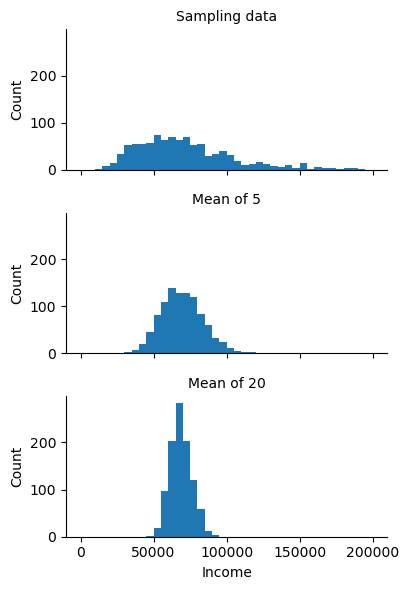

In [17]:
# gráfico para análise de distribuição amostral e distribuição estatística

g = sns.FacetGrid(results,col="type",col_wrap = 1, height = 2, aspect = 2)
g.map(plt.hist,"income",range = [0,200000], bins = 40)
g.set_axis_labels ("Income","Count")
g.set_titles("{col_name}")

In [18]:
# Teorema do Limite Central
# A distribuição das médias calculadas a partir de várias amostras (de uma amostra maior) terá a forma de uma curva normal (formato de sino), mesmo que a população não seja distribuída normalmente,
# desde que a amostra seja grande o suficiente
# O Teorema do Limite Central permite fórmulas para aproximação da distribuição normal, como a forma de distribuição-t

In [19]:
# Bootstrap
# técnica de reamostragem, onde as amostras usadas usam de reposição
# Não envolve a premissa de que os dados ou estatísticas amostrais possuam distribuição normal
# A amostra original é reamostrada várias vezes COM REPOSIÇÃO para estimar a distribuição amostral de uma estatística

# Algoritmo bootstrap
# 1- Tire uma reamostrage da amostra original COM REPOSIÇÃO, do mesmo tamanho
# 2- Calcule a estatística de interesse nessa reamostrage e grave
# 3- Repita os passos 1 e 2 R vezes (R arbitrário, tipicamente 1000 a 10000)
# 4- Use os R valores gravados para:
#    - calcular o erro padrão (std dos R valores)
#    - calcular o viés (média dos R valores - estatística original)
#    - construir intervalo de confiança (percentis 2.5% e 97.5%)
#    - plotar histograma para visualizar a distribuição amostral

In [20]:
# Bootstrap usando o método resample de scikit-learn
from sklearn.utils import resample
results = []
for nrepeat in range (1000):
    sample = resample(loans_income["x"])
    results.append(sample.median())
results = pd.Series(results)
print("Bootstrap Statistics:")
print(f"original: {loans_income['x'].median()}")
print(f"bias: {results.mean() - loans_income["x"].median()}") #mede o viés do amostrador
print(f"std. error: {results.std()}")

Bootstrap Statistics:
original: 62000.0
bias: -88.82600000000093
std. error: 244.14791403558473


In [21]:
# Resumo de bootstrap
# O que é — reamostrage com reposição para estimar a distribuição amostral de qualquer estatística sem premissa de normalidade.
# Como funciona — sorteia R amostras da original com reposição, calcula a estatística em cada uma, usa as R estatísticas para medir variabilidade.
# O que entrega — erro padrão, viés e intervalo de confiança do estimador.

In [22]:
results = []
for nrepeat in range (1000):
    sample = resample(jobs["salary"])
    results.append(sample.mean())
results = pd.Series(results)
print("Bootstrap Statistics:")
print(f"original: {jobs["salary"].mean()}")
print (f"bootstrap mean: {results.mean()}")
print(f"bias: {results.mean() - jobs["salary"].mean()}") #mede o viés do amostrador
print(f"std. error: {results.std()}")

Bootstrap Statistics:
original: 149057.5142615677
bootstrap mean: 149075.16578956266
bias: 17.65152799495263
std. error: 551.6218627458975


In [23]:
jobs

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,work_setting,company_location,company_size,job_category
0,2024,Entry-level,Freelance,Applied Data Scientist,30000,USD,30000,United Kingdom,Remote,United Kingdom,M,Data Science and Research
1,2024,Executive,Full-time,Business Intelligence,230000,USD,230000,United States,In-person,United States,M,BI and Visualization
2,2024,Executive,Full-time,Business Intelligence,176900,USD,176900,United States,In-person,United States,M,BI and Visualization
3,2024,Senior,Full-time,Data Architect,171210,USD,171210,Canada,In-person,Canada,M,Data Architecture and Modeling
4,2024,Senior,Full-time,Data Architect,92190,USD,92190,Canada,In-person,Canada,M,Data Architecture and Modeling
...,...,...,...,...,...,...,...,...,...,...,...,...
14194,2021,Senior,Full-time,Data Specialist,165000,USD,165000,United States,Remote,United States,L,Data Management and Strategy
14195,2020,Senior,Full-time,Data Scientist,412000,USD,412000,United States,Remote,United States,L,Data Science and Research
14196,2021,Mid-level,Full-time,Principal Data Scientist,151000,USD,151000,United States,Remote,United States,L,Data Science and Research
14197,2020,Entry-level,Full-time,Data Scientist,105000,USD,105000,United States,Remote,United States,S,Data Science and Research


In [ ]:
# Distribuição normal
# Erro - diferença entre um dado (ponto) e o valor previsto ou médio
# Padronizar - Subtrair a média e dividir pelo desvio padrão
# Parâmetros: média (em torno da qual todas as medidas se espalham) e desvio padrão (que diz quão espalhada é a distribuição)